<a href="https://colab.research.google.com/github/emmagiometti/Glaciers_GlaciatedLandscapesA26/blob/main/supraglacial_q_copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/atedstone/unil_envi_ggl_hydrology_practicals/blob/main/supraglacial_q.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical: Interpreting supraglacial melt and discharge

This practical examines three datasets:

1. Ablation at Moulin L41A (Chandler et al., 2021; https://doi.pangaea.de/10.1594/PANGAEA.926842)
2. Meltwater input hydrograph into Moulin L41A (Chandler et al., 2021; https://doi.pangaea.de/10.1594/PANGAEA.926844)
3. Meteorology/surface energy balance at nearby weather station KAN_M (PROMICE; https://doi.org/10.22008/FK2/IW73UU/G9NKYS)

The 'Download' block below downloads both the moulin datasets directly from their original DOI/URL. The weather station data has been prepared specifically for this course, so is downloaded from an UNIL Sharepoint store.

In [1]:
# Install ipympl so that we can use interactive plots
!pip install ipympl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ipympl]


**Important!** If this is the first time you are running the Notebook, restart your session **now** using the menu 'Runtime... Restart session'. You don't need to run the above cell again afterwards, you can continue with the rest of the Notebook.

In [1]:
# Activate ipympl in Colab
from google.colab import output
output.enable_custom_widget_manager()

In [2]:
# Packages for data download
import requests
import os

In [3]:
# Packages for data analysis
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib widget

## Download the data

In [4]:
files = {'Moulin_L41A_ice_ablation.tab': 'https://doi.pangaea.de/10.1594/PANGAEA.926842?format=textfile',
         'Moulin_L41A_Q.tab': 'https://doi.pangaea.de/10.1594/PANGAEA.926844?format=textfile',
         'AWS_KAN_M_2012.csv': 'https://unils-my.sharepoint.com/:x:/g/personal/andrew_tedstone_unil_ch/IQD2Lwevmxs2QbywUNCi0sgaAbu2EHvpxQMmLbGxESzF7IM?download=1'
}
for f in files:
    if os.path.exists(f):
        print('File already downloaded.')
    else:
        print('Downloading...')
        response = requests.get(files[f])
        open(f, 'wb').write(response.content)
print('Done.')

File already downloaded.
File already downloaded.
File already downloaded.
Done.


## Open the datasets using Pandas

In [5]:
ablation = pd.read_csv('Moulin_L41A_ice_ablation.tab', sep=r'\t', skiprows=19, parse_dates=True, index_col=0, engine='python')

In [6]:
discharge = pd.read_csv('Moulin_L41A_Q.tab', sep=r'\t', skiprows=20, parse_dates=True, index_col=0, engine='python')

In [7]:
aws = pd.read_csv('AWS_KAN_M_2012.csv', parse_dates=True, index_col='time')

## Initial look at dataset structure

In [8]:
# In Jupyter Notebook, entering the name of a Pandas DataFrame prints its head and foot to screen
ablation

,Ablation [mm],Ablation [±]
Date/Time,,
2012-05-30,36,6
2012-05-31,32,15
2012-06-01,21,9
2012-06-02,11,9
2012-06-03,3,6
...,...,...
2012-08-07,16,11
2012-08-08,11,5
2012-08-09,6,6


In [9]:
# We can also get some basic statistics calculated over the whole DataFrame
ablation.describe()

,Ablation [mm],Ablation [±]
count,74.000000,74.000000
mean,24.675676,8.445946
std,17.230992,3.896405
min,-8.000000,2.000000
25%,11.250000,5.250000
50%,22.500000,8.000000
75%,33.000000,11.000000
max,91.000000,19.000000


In [10]:
discharge

,Q hour mean [m**3/s],Q hour min [m**3/s],Q hour max [m**3/s]
Date/Time,,,
2012-06-16 13:00:00,1.175341,0.316950,0.433981
2012-06-16 14:00:00,1.260791,0.327451,0.442334
2012-06-16 15:00:00,1.451227,0.348790,0.459140
2012-06-16 16:00:00,1.761579,0.379919,0.484387
2012-06-16 17:00:00,2.206190,0.423898,0.524717
...,...,...,...
2012-08-09 16:00:00,0.916114,0.280071,0.403396
2012-08-09 17:00:00,0.978514,0.289761,0.411665
2012-08-09 18:00:00,1.125895,0.310547,0.428826


Notice that there are three columns of data in the discharge dataset. The columns with 'min' and 'max' in the titles are actually the - and + error bounds corresponding to the 95% confidence intervals. They are *not* the absolute min and max values. See the plotting code below for an example of how to use these columns.

In [11]:
aws

,dlr,ulr,dsr_cor,usr_cor,dlhf_u,dshf_u,albedo,cc,z_surf_combined,snow_height
time,,,,,,,,,,
2012-01-01 00:00:00,185.8186,188.3312,0.0,0.0,0.2405,2.5613,NaN,0.9729,-3.3828,0.2511
2012-01-01 01:00:00,183.5768,188.0959,0.0,0.0,0.1796,1.2357,NaN,0.9974,-3.3804,0.2535
2012-01-01 02:00:00,177.3267,184.1451,0.0,0.0,0.2481,2.6895,NaN,0.9772,-3.3803,0.2536
2012-01-01 03:00:00,170.2476,178.4706,0.0,0.0,0.3806,5.9475,NaN,0.9686,-3.3796,0.2543
2012-01-01 04:00:00,167.8691,175.3584,0.0,0.0,0.3667,6.2462,NaN,0.9857,-3.3792,0.2547
...,...,...,...,...,...,...,...,...,...,...
2012-12-31 19:00:00,135.2082,188.4147,0.0,0.0,0.6702,54.7026,NaN,0.1589,-5.3857,0.3139
2012-12-31 20:00:00,136.2584,191.4930,0.0,0.0,1.3260,60.2434,NaN,0.1332,-5.3866,0.3130
2012-12-31 21:00:00,136.4896,192.9934,0.0,0.0,1.3739,57.6791,NaN,0.1261,-5.3868,0.3128


Here we have measurements acquired by a nearby automatic weather station, the PROMICE KAN_M site. The columns are as follows:

### Surface energy budget variables

All in units of watts per square metre.

* `dlr`: Downwards longwave radiation
* `ulr`: Upwards longwave radiation
* `dsr_cor`: Downwards shortwave radiation, corrected for station tilt etc
* `usr_cor`: Upwards shortwave radiation, corrected for station tilt etc
* `dlhf_u`: Latent heat flux
* `dshf_u`: Sensible heat flux

### Other selected variables

* `snow_height`: as it suggests, the thickness of the snowpack lying on top of the bare ice. Units of metres.
* `z_surf_combined`: total change in surface height, i.e. combining the snow accumulation and melt (which accumulates around the weather station) and the ice melt (which causes the station itself to sink down with the ice surface, therefore ice melt cannot be tracked by the `snow_height` variable). Units of metres.
* `cc`: an estimate of cloud cover, percent.
* `albedo`: in-situ broadband (shortwave) albedo (unitless ratio).

Attention: when looking at `snow_height` and `z_surf_combined`, remember that snow and ice have very different densities - a 1 cm reduction in snow height might only be around 0.5 cm water equivalent, whereas a 1 cm reduction in ice height generates around 0.9 cm water equivalent.

## Plot the data

/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


Text(0, 0.5, 'Q ($m^3s^{-1}$)')

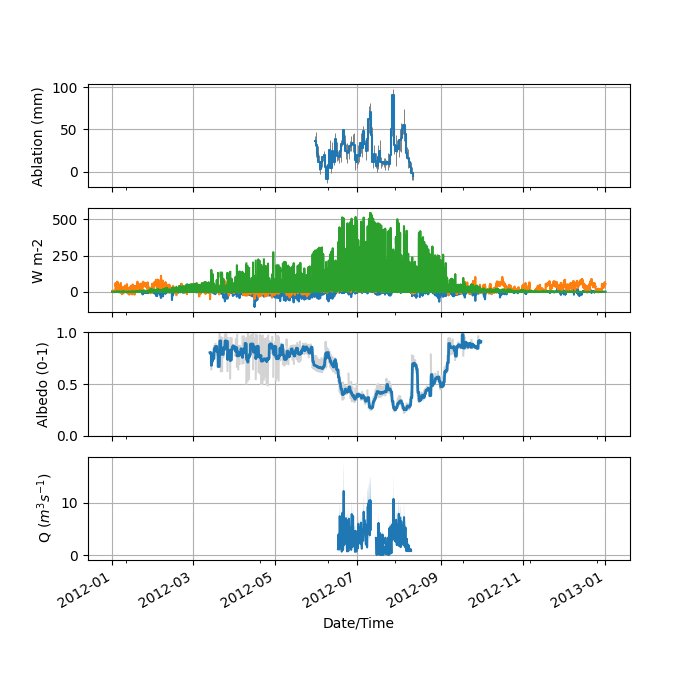

In [12]:
# Set up the figure and subplots
plt.figure(figsize=(7,7))
ax_ablat = plt.subplot(411)
ax_seb = plt.subplot(412, sharex=ax_ablat)
ax_alb = plt.subplot(413, sharex=ax_ablat)
ax_disch = plt.subplot(414, sharex=ax_ablat)

# Ablation data
ax_ablat.errorbar(ablation.index+pd.Timedelta(hours=12), ablation['Ablation [mm]'], yerr=ablation['Ablation [±]'],
                  drawstyle='steps-mid', elinewidth=0.7, ecolor='gray')
ax_ablat.grid()
ax_ablat.set_ylabel('Ablation (mm)')

# Surface energy balance data
ax_seb.plot(aws.index, aws.dlhf_u, label='Latent')
ax_seb.plot(aws.index, aws.dshf_u, label='Sensible')
# Calculate net shortwave radiation
swnet = aws.dsr_cor - aws.usr_cor
ax_seb.plot(swnet.index, swnet, label='SWnet')
ax_seb.grid()
ax_seb.set_ylabel('W m-2')

# Albedo
ax_alb.plot(aws.index, aws.albedo, label='Albedo', color='lightgrey')
ax_alb.plot(aws.index, aws.albedo.rolling('24h').mean(), label='Albedo smoothed 24h', linewidth=2)
ax_alb.set_ylim(0, 1)
ax_alb.grid()
ax_alb.set_ylabel('Albedo (0-1)')

# Discharge at the confidence bounds
lower_q = discharge['Q hour mean [m**3/s]'] + discharge['Q hour max [m**3/s]']
upper_q = discharge['Q hour mean [m**3/s]'] - discharge['Q hour min [m**3/s]']

# Plot as a filled area
ax_disch.fill_between(lower_q.index, lower_q, upper_q, alpha=0.5)
discharge['Q hour mean [m**3/s]'].plot(ax=ax_disch)
ax_disch.grid()
ax_disch.set_ylabel(r'Q ($m^3s^{-1}$)')

# To plot vertical lines:
#ax_disch.axvline('2012-07-08', color='red')

# To plot shaded areas:
#ax_disch.axvspan('2012-07-09', '2012-07-11', alpha=0.3, color='red')

## Questions / Exercises

### Describe any relationships you can see between ablation and the main components of the energy budget.

Positive relationship; when the energy budget increases, the ablation will increase as well. Difficult to tell but it seems as if there is a slight delay in ablation repsonse time to an increase in W m-2.

peaks in ablation occur at the same time as peaks in sensible heat, and peaks in sensible heat are shortly folowed by drops in albedo.

drops in albedo coincide with rises in discharge, and elevated ablation coincide with elevated discharge

very rapid processes occurring,

### To what degree does albedo co-vary with the surface energy budget?

Inverse trend, albedo is decreasing at the same time as the surface energy budget is increasing?

### Based only on what you see in these data, do you think that you are looking at snow melt or ice melt?

we can see moment albedo starts to plummet from dirty snow levels, which means that snow cover is gone and the regime has changed to ice melt.

when you are below 0.5 you are definitely observing bare ice.

net short wave radiation: amount of energy available for melting, which is downwelling shortwave radiation

SWnet (in green) increases due to albedo reduced, because you have more energy available for potential melt

look in AWS dataframe, you can plot downwelling SWradiation and upwelling SWradiation to see how they co-vary, should find that downwelling peaks in june?

energy budget measured by in-situ weather station

discharge: starting point for analysis, very important and trying to understanding variations in discharge hydrograph

in late season the discharge hydrograph drops to 0 every day, in the middle of the night: pockets of snow cover store water and release a consistent base flow 24 hours of day, but as these snow patches melt away there is no base flow storage to provide consistent flow, which is why the river dries up every night
- water is still traveling over a large area but the routing times are larger and it's more ice melt dominated than snow melt later in the season



### How much water flows into the moulin per day, expressed as Olympic swimming pools?

In [13]:
# Resample the discharge data to daily sums, matching sampling of ablation data
# Note the min_count is set to the number of hours in a day, so that we only
# look at days with full temporal data
# We multiply by 60secs * 60 mins to convert m3s-1 into m3day-1.
q_daily = discharge['Q hour mean [m**3/s]'].resample('1D').sum(min_count=24) * 60 * 60

In [14]:
vol_pool_m3 = 2500
# calculate the mean daily discharge and divide it by this volume.
mean_daily_q_m3 = q_daily.mean()
mean_daily_q_pools = mean_daily_q_m3 / vol_pool_m3
print(f"Mean daily discharge: {mean_daily_q_pools:.2f} Olympic swimming pools")

Mean daily discharge: 125.92 Olympic swimming pools


### Is there a significant correlation between daily ablation and daily discharge?

*To answer this question you will find the code below helpful.*

In [15]:
import statsmodels.api as sm
# Do an 'Ordinary Least Squares' regression
# See https://www.statsmodels.org/dev/generated/statsmodels.regression.linear_model.OLS.html for more information

# Cut ablation data to same time period as discharge (discharge is shorter)
X = ablation.loc[q_daily.index[0]:q_daily.index[-1]]['Ablation [mm]']

# Get the discharge mean series
Y = q_daily

# Some days are missing data; we 'drop' (remove) those days.
model = sm.OLS(Y, sm.add_constant(X), missing='drop')

fit = model.fit()
fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     Q hour mean [m**3/s]   R-squared:                       0.624
Model:                              OLS   Adj. R-squared:                  0.615
Method:                   Least Squares   F-statistic:                     69.65
Date:                  Wed, 18 Nov 2026   Prob (F-statistic):           1.85e-10
Time:                          15:03:07   Log-Likelihood:                -559.31
No. Observations:                    44   AIC:                             1123.
Df Residuals:                        42   BIC:                             1126.
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          1.286e+05   2.55e+04      5.038      0.000    7.71e+04     1.8e+05
Ablation [mm]  6012.2927    720.386      8.346      0.000    4558.495    7466.090
==============================================================================
Omnibus:                        2.113   Durbin-Watson:                   0.994
Prob(Omnibus):                  0.348   Jarque-Bera (JB):                1.174
Skew:                           0.318   Prob(JB):                        0.556
Kurtosis:                       3.485   Cond. No.                         73.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Put your answer to this question below. Remember to consider the significance of the test result.

The R-squared value is only 0.624 which implies a relatively poor correlation between the two.

### Is this value what you expected, and why?

In [ ]:
# I am not sure. On the graph it appears that they would be more correlated,

### When is peak daily discharge? Why might this be?

To answer this question and the next one, there are at least a couple of approaches that you could use:

- Manual visual interpretation of diurnal values
- Time series resampling -- see the `q_daily` example above, you can supply different functions to the `sum()` operation that we used there.

### When is base (minimum) daily discharge? Why might this be?

### You are following a range of other courses related to data analysis during your studies. What other method(s) might you use to extend this analysis?